In [1]:
from dfft.utils.files import get_path
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import re
import json

In [ ]:
def extract_time(d):
    m = re.match(r"(\d{8}_\d{6})", os.path.basename(d))
    return m.group(1) if m else ""

def get_lastest_exp(base_dir):
    exp_dirs = [os.path.join(base_dir, d) for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d))]
    exp_dirs = sorted(exp_dirs, key=extract_time, reverse=True)
    return exp_dirs[-1]

In [144]:
names = ['moment-small', 'moment-base', 'moment-large']
configs=["-finetuned", "-lora"]
losses = ["", "-decision"]
models = [ name + c + l for name in names for c in configs for l in losses]
models.append('moment-small-zeroshot')
models.append('moment-base-zeroshot')
models.append('moment-large-zeroshot')

In [145]:
#Create a table of regret, mse by model and data split
all = []
for model in models:
    base_dir = get_path(f"results\\experiments\\{model}\\NEMA")
    exp_dir = get_lastest_exp(base_dir)
    df = pd.read_parquet(exp_dir + "/results.parquet")
    #Compute regret
    result = df.groupby('split')[['true_profit', 'real_profit']].sum()
    result['model'] = model
    result['regret'] = (result['true_profit'] - result['real_profit']) / result['true_profit']
    result['regret'] = (result['regret'] * 100).round(1)
    all.append(result.reset_index())

regret = pd.concat(all, axis= 0)
#Reshape data
regret = regret[['model', 'split', 'regret']]
regret = regret.pivot(index='model', columns='split', values='regret')
regret = regret.sort_values('model')
print(regret)

FileNotFoundError: [Errno 2] No such file or directory: 'H:\\My Drive\\Study\\Sem 2\\10707 Advanced Deep Learning\\Project\\decision-focused-fine-tuning\\results\\experiments\\moment-small-finetuned\\NEMA\\20260423_173539_v2/results.parquet'

In [146]:
all=[]
for model in models:
    base_dir = get_path(f"results\\experiments\\{model}\\NEMA")
    exp_dir = get_lastest_exp(base_dir)
    with open(exp_dir + "/results.json", 'r') as f:
            data = json.load(f)
    df = pd.DataFrame([model], columns=["model"])
    df["test_mse"] = data['test_results']['mse']
    df["val_mse"] = data['final_val_results']['mse']
    df["train_mse"] = data['final_train_results']['mse']
    all.append(df)

mse  = pd.concat(all, axis= 0)
print(mse)

                             model     test_mse      val_mse    train_mse
0           moment-small-finetuned  1425.428833  1228.364014   957.241272
0  moment-small-finetuned-decision  2459.853760  1679.445801  2157.851074
0                moment-small-lora  1426.075806  1227.158936   982.956726
0       moment-small-lora-decision  2521.183105  1719.716431  2240.185791
0            moment-base-finetuned  1449.115356  1229.195068   923.970520
0   moment-base-finetuned-decision  2356.553955  1628.137573  2105.221680
0                 moment-base-lora  1451.318970  1229.216675   910.887207
0        moment-base-lora-decision  2809.929688  1872.331787  2566.955322
0           moment-large-finetuned  1409.101318  1242.135376   933.712585
0  moment-large-finetuned-decision  2250.712891  1617.128174  2015.442627
0                moment-large-lora  1406.375366  1240.238037   953.742920
0       moment-large-lora-decision  2253.629883  1615.110596  2008.418701
0            moment-small-zeroshot  21

In [147]:
metrics = pd.merge(mse, regret, on='model', how='inner')
print(metrics.sort_values('model'))

                              model     test_mse      val_mse    train_mse  \
4             moment-base-finetuned  1449.115356  1229.195068   923.970520   
5    moment-base-finetuned-decision  2356.553955  1628.137573  2105.221680   
6                  moment-base-lora  1451.318970  1229.216675   910.887207   
7         moment-base-lora-decision  2809.929688  1872.331787  2566.955322   
13             moment-base-zeroshot  2153.526855  1523.163330  1962.787231   
8            moment-large-finetuned  1409.101318  1242.135376   933.712585   
9   moment-large-finetuned-decision  2250.712891  1617.128174  2015.442627   
10                moment-large-lora  1406.375366  1240.238037   953.742920   
11       moment-large-lora-decision  2253.629883  1615.110596  2008.418701   
14            moment-large-zeroshot  2087.747070  1483.763428  1918.667480   
0            moment-small-finetuned  1425.428833  1228.364014   957.241272   
1   moment-small-finetuned-decision  2459.853760  1679.445801  2

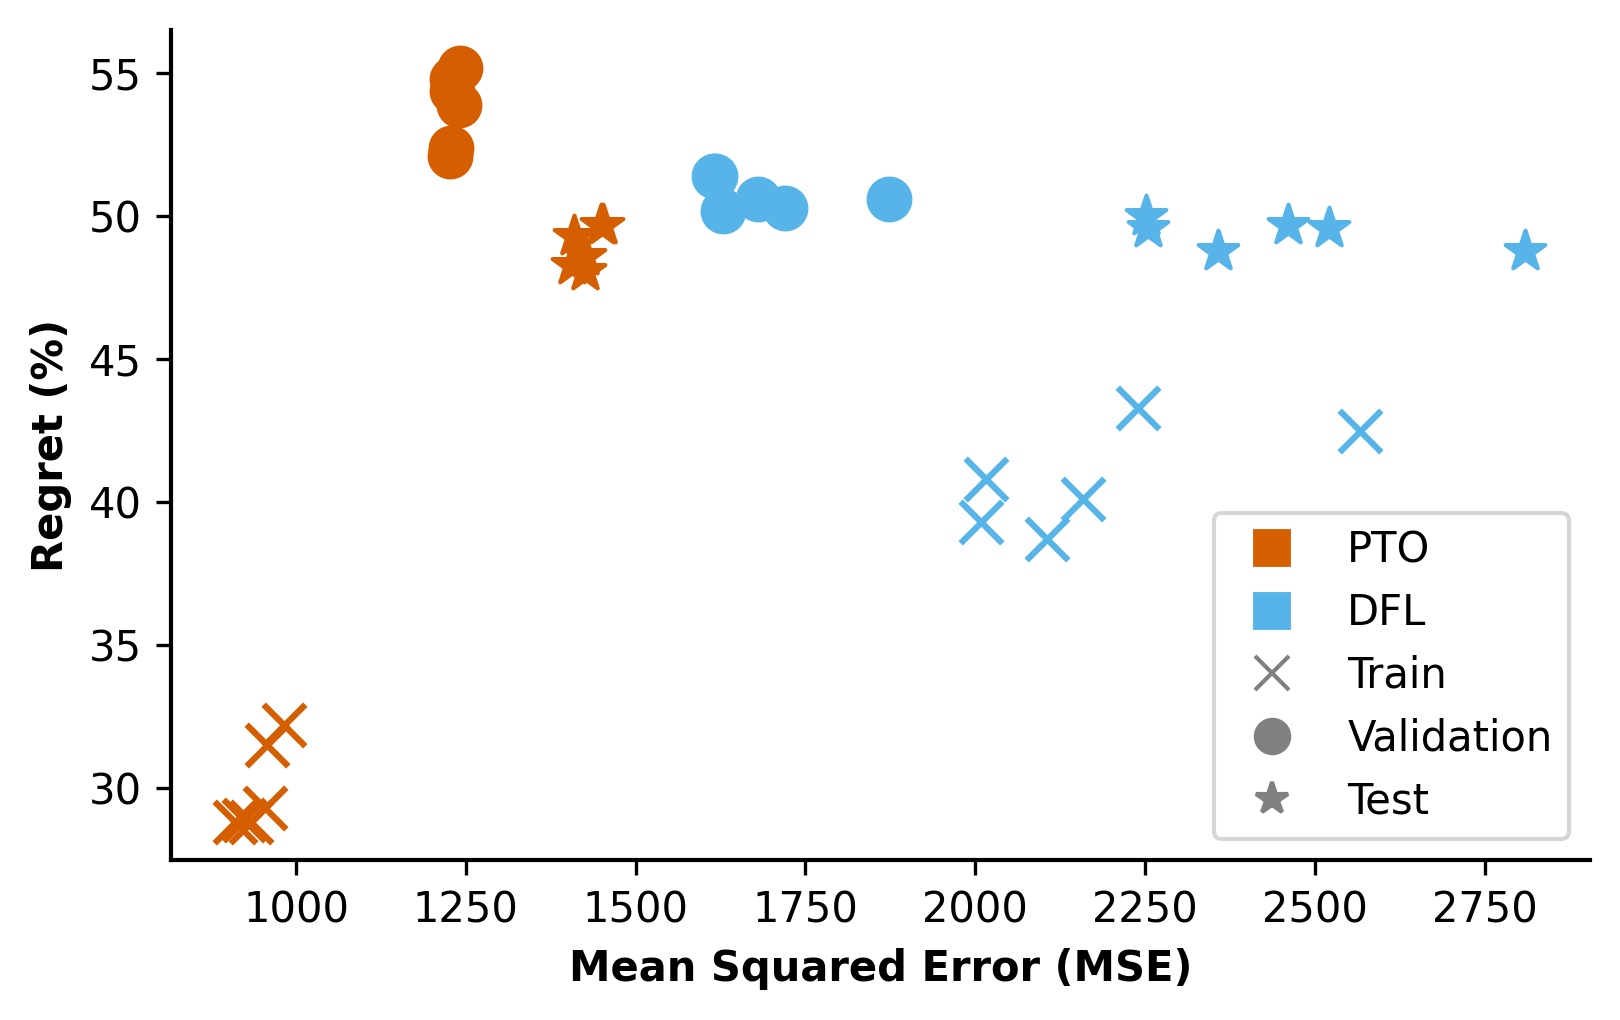

In [156]:
#Create a scatter plot of Regret vs. MSE
dfl = metrics.loc[metrics['model'].str.contains('decision')]
pto = metrics.loc[(~metrics['model'].str.contains('decision')) & (~metrics['model'].str.contains('zeroshot'))]

plt.style.use('default')
fig, ax = plt.subplots(figsize=(5.5, 3.5), dpi=300)

ax.scatter(dfl["train_mse"], dfl["train"], color='#56B4E9', marker='x', s=100, label='Train (dfl)')
ax.scatter(dfl["val_mse"], dfl["val"], color='#56B4E9', marker='o', s=100, label='Val (dfl)')
ax.scatter(dfl["test_mse"], dfl["test"], color='#56B4E9', marker='*', s=100, label='Test (dfl)')

ax.scatter(pto["train_mse"], pto["train"], color='#D55E00', marker='x', s=100, label='Train (pto)')
ax.scatter(pto["val_mse"], pto["val"], color='#D55E00', marker='o', s=100, label='Val (pto)')
ax.scatter(pto["test_mse"], pto["test"], color='#D55E00', marker='*', s=100, label='Test (pto)')

ax.set_xlabel('Mean Squared Error (MSE)', fontweight='bold', fontsize=10)
ax.set_ylabel('Regret (%)', fontweight='bold', fontsize=10)

legend_elements = [
    # Color indicators
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#D55E00', markersize=10, label='PTO'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#56B4E9', markersize=10, label='DFL'),
    # Marker indicators
    Line2D([0], [0], color='gray', marker='x', linestyle='None', markersize=8, label='Train'),
    Line2D([0], [0], color='gray', marker='o', linestyle='None', markersize=8, label='Validation'),
    Line2D([0], [0], color='gray', marker='*', linestyle='None', markersize=8, label='Test')

]


ax.spines['bottom'].set_linewidth(1.0)
ax.spines['left'].set_linewidth(1.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(handles=legend_elements, loc='lower right', frameon=True, fontsize=10)

plt.tight_layout()
plt.savefig("plots/regret_vs_mse.pdf", format='pdf', bbox_inches='tight') 
plt.show()

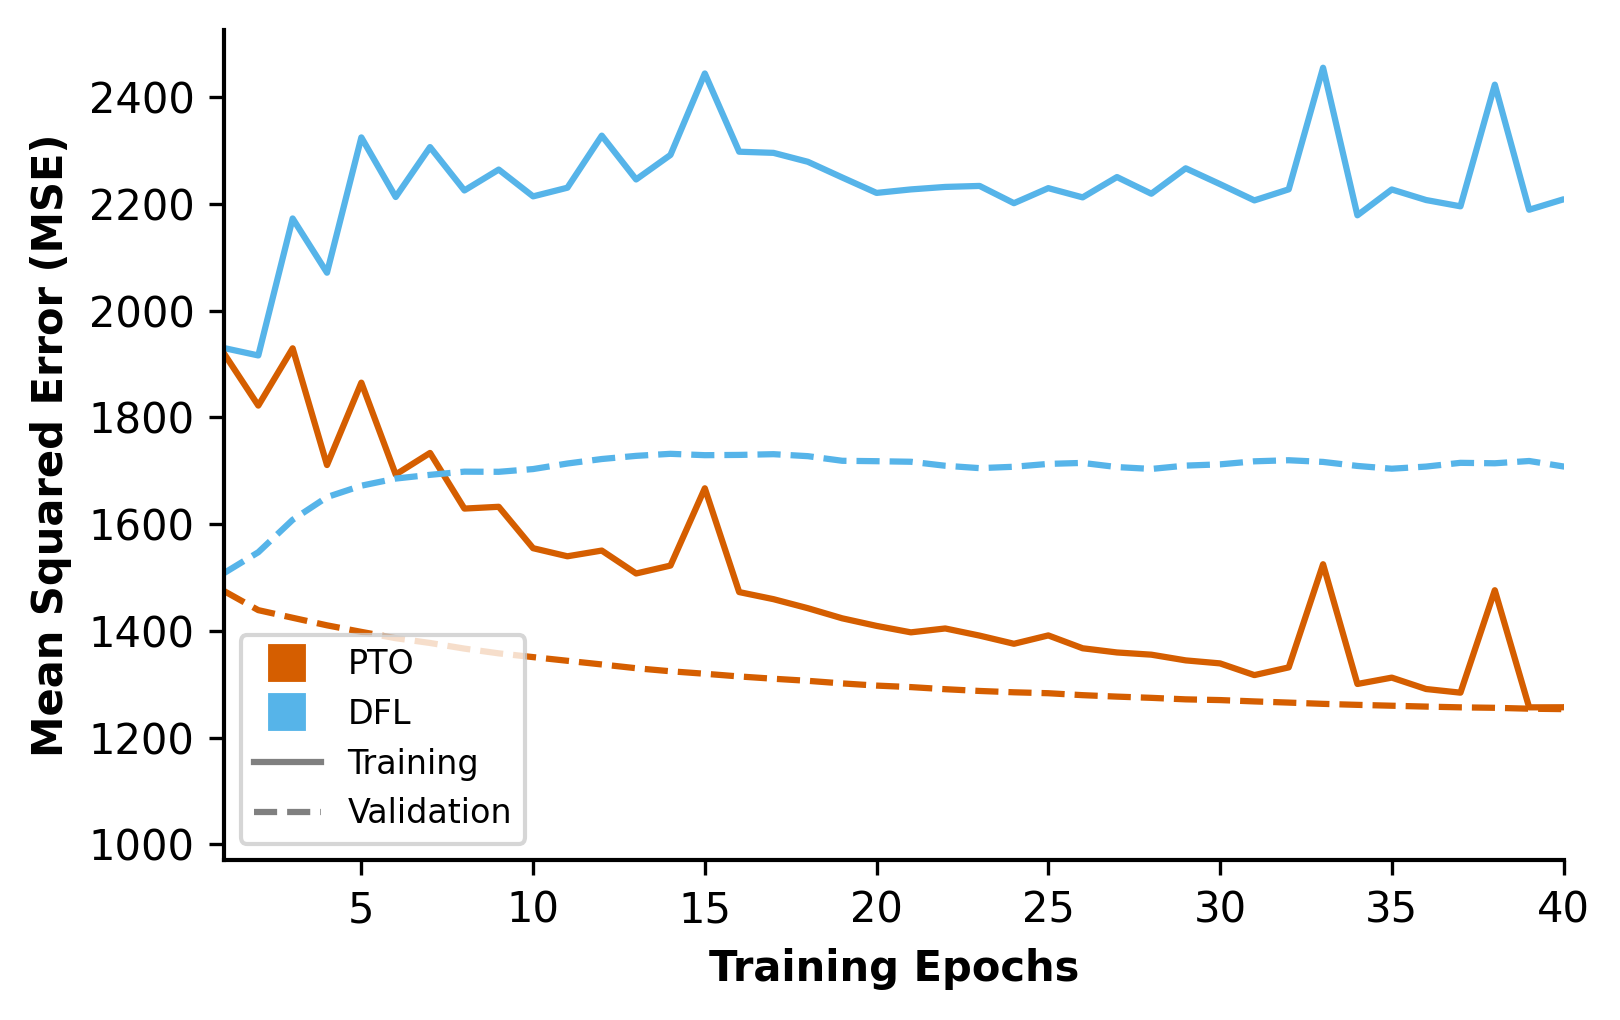

In [154]:
#Plot trajectories for moment-small-lora


#Read training data

#moment-small-lora
base_dir = get_path(f"results\\experiments\\moment-small-lora\\NEMA")
exp_dir = get_lastest_exp(base_dir)
with open(exp_dir + "/results.json", 'r') as f:
        pto = json.load(f)

#moment-small-lora-decision
base_dir = get_path(f"results\\experiments\\moment-small-lora-decision\\NEMA")
exp_dir = get_lastest_exp(base_dir)
with open(exp_dir + "/results.json", 'r') as f:
        dfl = json.load(f)
dfl["training_history"]["train"]["mse"]

#Generate plot
plt.style.use('default')
fig, ax = plt.subplots(figsize=(5.5, 3.5), dpi=300)

#Training
ax.plot(
        np.arange(start=1, stop=len(dfl["training_history"]["train"]["mse"]) +1), 
        dfl["training_history"]["train"]["mse"],
        linestyle= "-",
        color = '#56B4E9'
)

ax.plot(
        np.arange(start=1, stop=len(pto["training_history"]["train"]["mse"]) +1), 
        pto["training_history"]["train"]["mse"],
        linestyle= "-",
        color = '#D55E00'
)

#Validation
ax.plot(
        np.arange(start=1, stop=len(dfl["training_history"]["train"]["mse"]) +1), 
        dfl["training_history"]["val"]["mse"],
        linestyle= "--",
        color = '#56B4E9'
)

ax.plot(
        np.arange(start=1, stop=len(pto["training_history"]["train"]["mse"]) +1), 
        pto["training_history"]["val"]["mse"],
        linestyle= "--",
        color = '#D55E00'
)


ax.set_xlabel('Training Epochs', fontweight='bold', fontsize=10)
ax.set_ylabel('Mean Squared Error (MSE)', fontweight='bold', fontsize=10)

ax.set_xlim(xmin=1, xmax=40)

legend_elements = [
    # Color indicators
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#D55E00', markersize=10, label='PTO'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#56B4E9', markersize=10, label='DFL'),
    # Marker indicators
    Line2D([0], [0], color='gray', linestyle='-', label='Training'),
    Line2D([0], [0], color='gray', linestyle='--', label='Validation')
]

ax.spines['bottom'].set_linewidth(1.0)
ax.spines['left'].set_linewidth(1.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend
ax.legend(handles=legend_elements, loc='best', frameon=True, fontsize=8)

plt.tight_layout()
plt.savefig("plots/mse_traj.pdf", format='pdf', bbox_inches='tight') 
plt.show()

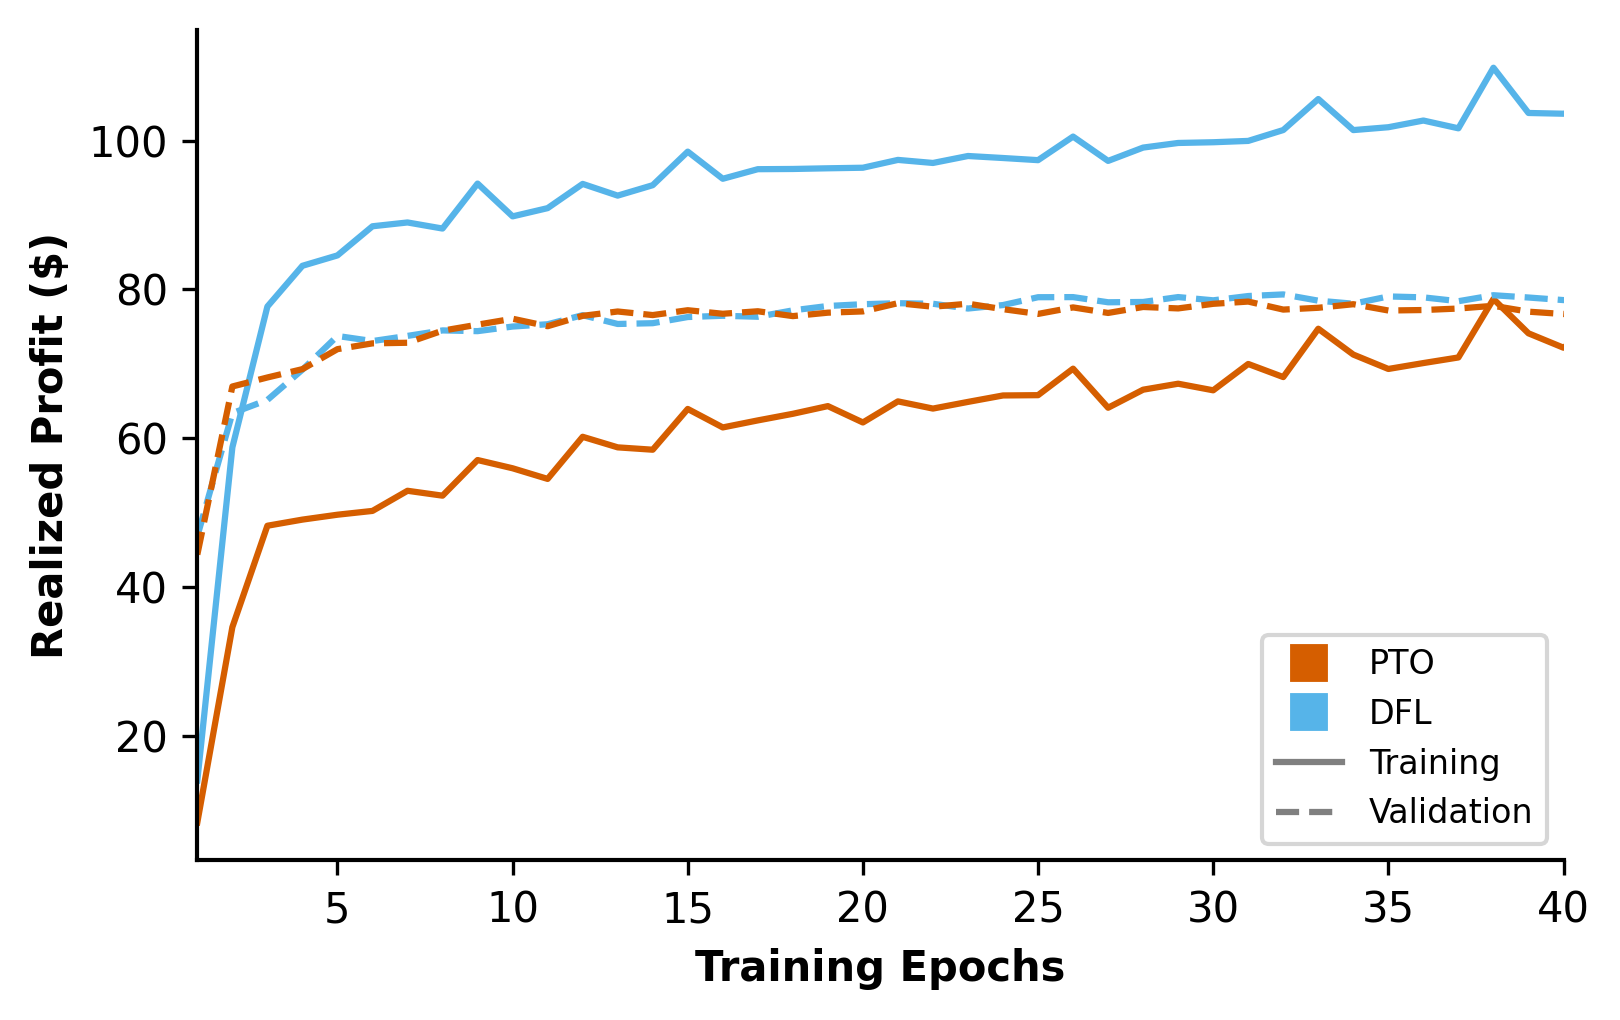

In [155]:
#Generate plot
plt.style.use('default')
fig, ax = plt.subplots(figsize=(5.5, 3.5), dpi=300)

#Training
ax.plot(
        np.arange(start=1, stop=len(dfl["training_history"]["train"]["mse"]) +1), 
        dfl["training_history"]["train"]["profit"],
        linestyle= "-",
        color = '#56B4E9'
)

ax.plot(
        np.arange(start=1, stop=len(pto["training_history"]["train"]["mse"]) +1), 
        pto["training_history"]["train"]["profit"],
        linestyle= "-",
        color = '#D55E00'
)

#Validation
ax.plot(
        np.arange(start=1, stop=len(dfl["training_history"]["train"]["mse"]) +1), 
        dfl["training_history"]["val"]["profit"],
        linestyle= "--",
        color = '#56B4E9'
)

ax.plot(
        np.arange(start=1, stop=len(pto["training_history"]["train"]["mse"]) +1), 
        pto["training_history"]["val"]["profit"],
        linestyle= "--",
        color = '#D55E00'
)


ax.set_xlabel('Training Epochs', fontweight='bold', fontsize=10)
ax.set_ylabel('Realized Profit ($)', fontweight='bold', fontsize=10)

ax.set_xlim(xmin=1, xmax=40)

legend_elements = [
    # Color indicators
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#D55E00', markersize=10, label='PTO'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#56B4E9', markersize=10, label='DFL'),
    # Marker indicators
    Line2D([0], [0], color='gray', linestyle='-', label='Training'),
    Line2D([0], [0], color='gray', linestyle='--', label='Validation')
]

ax.spines['bottom'].set_linewidth(1.0)
ax.spines['left'].set_linewidth(1.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend
ax.legend(handles=legend_elements, loc='best', frameon=True, fontsize=8)

plt.tight_layout()
plt.savefig("plots/profit_traj.pdf", format='pdf', bbox_inches='tight') 
plt.show()

In [95]:
base_dir = get_path(f"results\\experiments\\moment-small-lora-decision\\NEMA")
exp_dir = get_lastest_exp(base_dir)
dfl = pd.read_parquet(exp_dir + "/results.parquet")
#Compute regret
dfl['regret'] = (dfl['true_profit'] - dfl['real_profit']) / dfl['true_profit']
dfl['mse'] = dfl.apply(
    lambda row: np.mean((np.array(row['true']) - np.array(row['pred']))**2), 
    axis=1
)

dfl['pred_power'] = dfl.apply(
    lambda row: (np.array(row['pred_c_sol']) - np.array(row['pred_d_sol'])).tolist(), 
    axis=1

)
dfl['true_power'] = dfl.apply(
    lambda row: (np.array(row['true_c_sol']) - np.array(row['true_d_sol'])).tolist(), 
    axis=1
)

In [60]:
example_dfl = dfl[(dfl['sample_idx'] == 355) &(dfl['split'] == 'test')].iloc[0]

In [96]:
base_dir = get_path(f"results\\experiments\\moment-small-lora\\NEMA")
exp_dir = get_lastest_exp(base_dir)
pto = pd.read_parquet(exp_dir + "/results.parquet")
#Compute regret
pto['regret'] = (pto['true_profit'] - pto['real_profit']) / pto['true_profit']
pto['mse'] = pto.apply(
    lambda row: np.mean((np.array(row['true']) - np.array(row['pred']))**2), 
    axis=1
)

pto['pred_power'] = pto.apply(
    lambda row: (np.array(row['pred_c_sol']) - np.array(row['pred_d_sol'])).tolist(), 
    axis=1

)
pto['true_power'] = pto.apply(
    lambda row: (np.array(row['true_c_sol']) - np.array(row['true_d_sol'])).tolist(), 
    axis=1
)

In [62]:
example_pto = pto[(pto['sample_idx'] == 355) &(pto['split'] == 'test')].iloc[0]


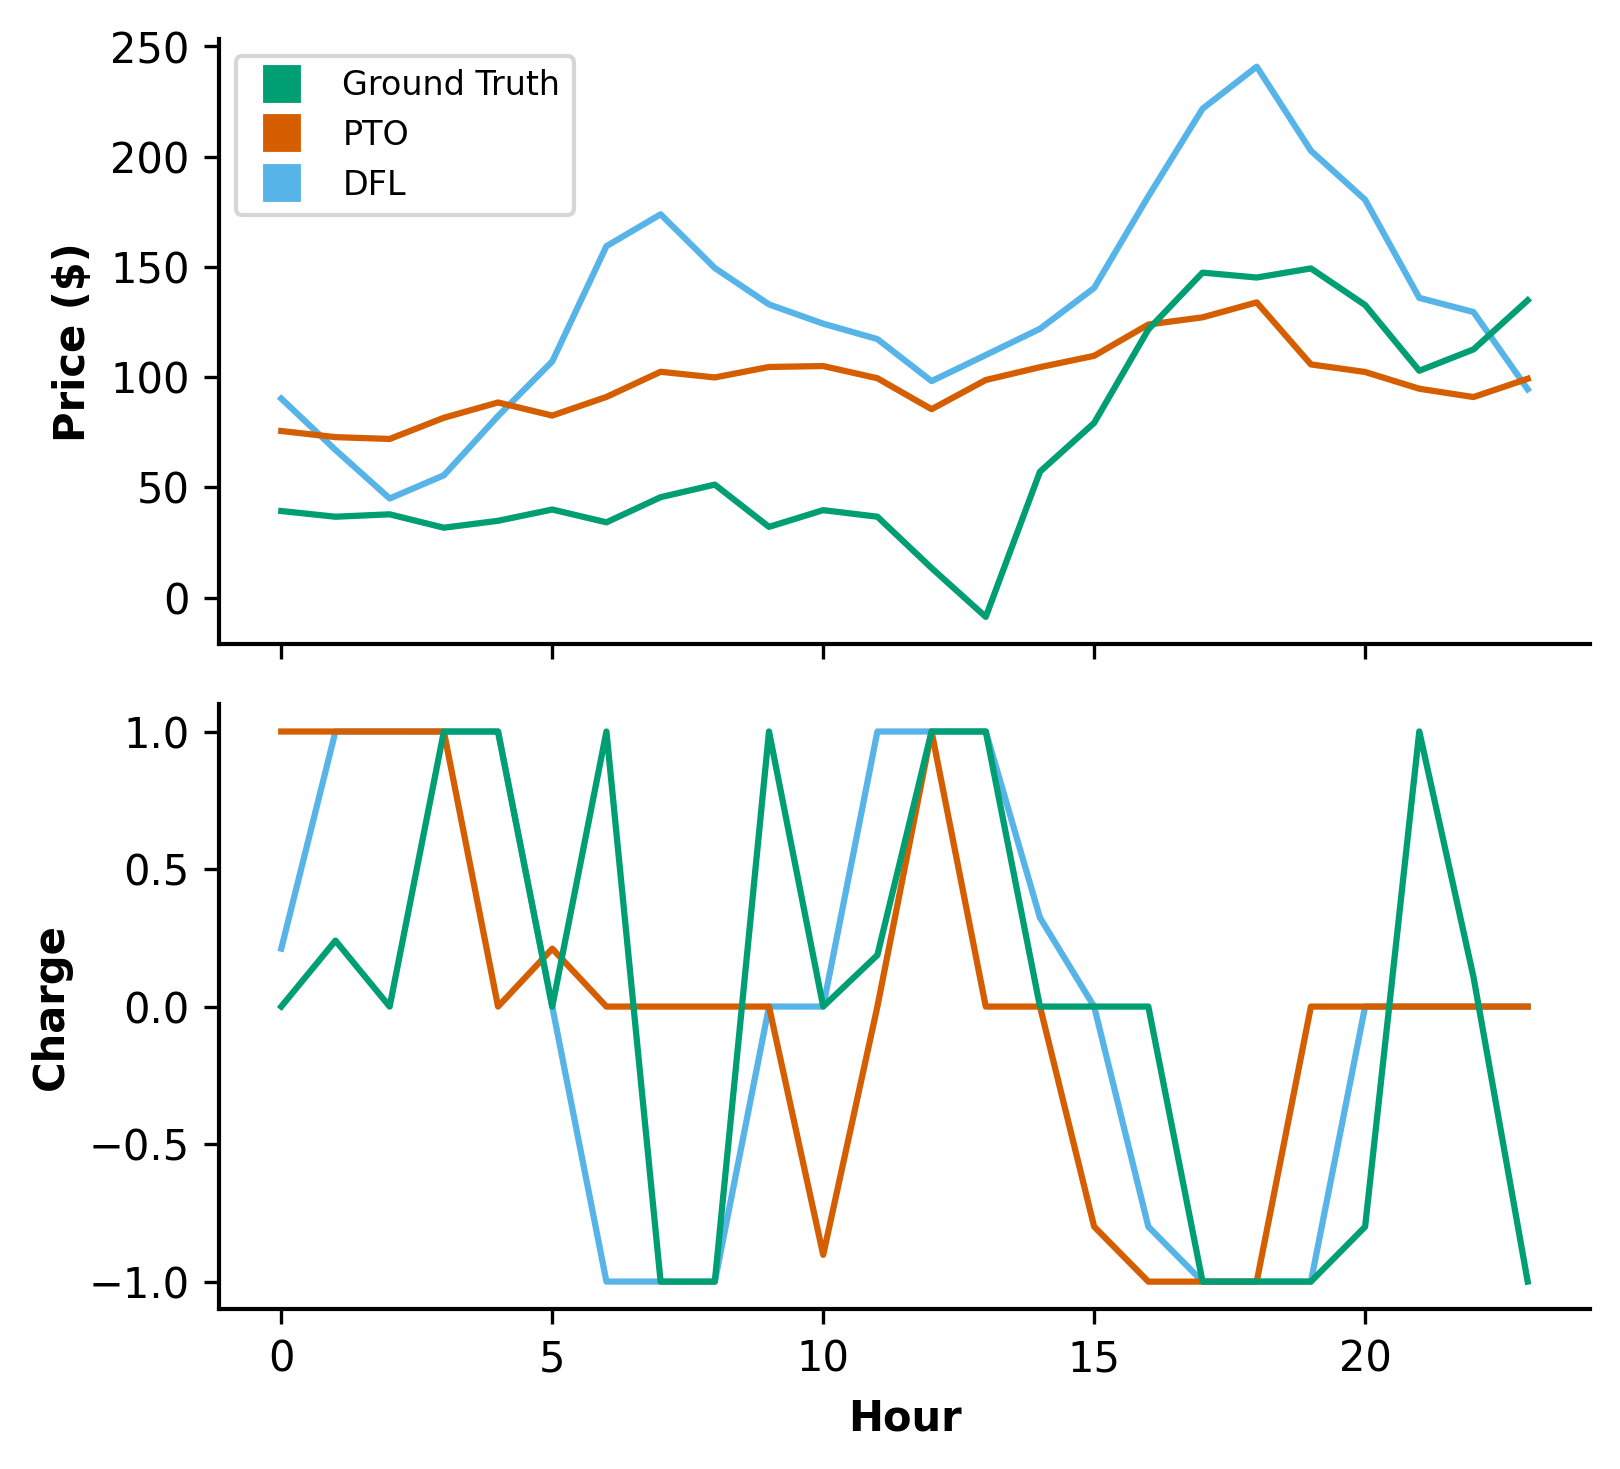

In [150]:
# Generate plot
plt.style.use('default')
# We increase the height slightly and create 2 subplots sharing the x-axis
fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(5.5, 5), dpi=300, sharex=True)

# --------------------------
# TOP PLOT (ax1): Price
# --------------------------
ax1.plot(example_dfl['pred'], linestyle="-", color='#56B4E9')
ax1.plot(example_pto['pred'], linestyle="-", color='#D55E00')
ax1.plot(example_dfl['true'], linestyle="-", color='#009E73')

ax1.set_ylabel('Price ($)', fontweight='bold', fontsize=10)

# --------------------------
# BOTTOM PLOT (ax2): Charging
# --------------------------
ax2.plot(example_dfl['pred_power'], linestyle="-", color='#56B4E9')
ax2.plot(example_pto['pred_power'], linestyle="-", color='#D55E00')
ax2.plot(example_dfl['true_power'], linestyle="-", color='#009E73') 


ax2.set_ylabel('Charge', fontweight='bold', fontsize=10)
ax2.set_xlabel('Hour', fontweight='bold', fontsize=10) 

# --------------------------
# Styling & Legends
# --------------------------
legend_elements = [
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#009E73', markersize=10, label='Ground Truth'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#D55E00', markersize=10, label='PTO'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#56B4E9', markersize=10, label='DFL')
]
ax1.legend(handles=legend_elements, loc='best', frameon=True, fontsize=8)

# Apply spine styling to BOTH axes
for ax in [ax1, ax2]:
    ax.spines['bottom'].set_linewidth(1.0)
    ax.spines['left'].set_linewidth(1.0)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Adjust layout so they don't overlap
plt.tight_layout()
plt.savefig("plots/example_decision_loss.pdf", format='pdf', bbox_inches='tight') 
plt.show()


In [127]:
true_train_strategy = np.std(pto.loc[pto['split']  == 'train', 'true_power'].to_list(), axis=0)
true_val_strategy = np.std(pto.loc[pto['split']  == 'val', 'true_power'].to_list(), axis=0)
true_test_strategy = np.std(pto.loc[pto['split']  == 'test', 'true_power'].to_list(), axis=0)

pto_train_strategy = np.std(pto.loc[pto['split']  == 'train', 'pred_power'].to_list(), axis=0)
pto_val_strategy = np.std(pto.loc[pto['split']  == 'val', 'pred_power'].to_list(), axis=0)
pto_test_strategy = np.std(pto.loc[pto['split']  == 'test', 'pred_power'].to_list(), axis=0)

dfl_train_strategy = np.std(dfl.loc[dfl['split']  == 'train', 'pred_power'].to_list(), axis=0)
dfl_val_strategy = np.std(dfl.loc[dfl['split']  == 'val', 'pred_power'].to_list(), axis=0)
dfl_test_strategy = np.std(dfl.loc[dfl['split']  == 'test', 'pred_power'].to_list(), axis=0)


true_test_lists = pto['true_power'].to_list()
pto_test_lists = pto['pred_power'].to_list()
dfl_test_lists = dfl['pred_power'].to_list()

# 2. Calculate Means
true_test_mean = np.mean(true_test_lists, axis=0)
pto_test_mean = np.mean(pto_test_lists, axis=0)
dfl_test_mean = np.mean(dfl_test_lists, axis=0)

# (You already calculated these in your code)
true_test_std = np.std(true_test_lists, axis=0)
pto_test_std = np.std(pto_test_lists, axis=0)
dfl_test_std = np.std(dfl_test_lists, axis=0)

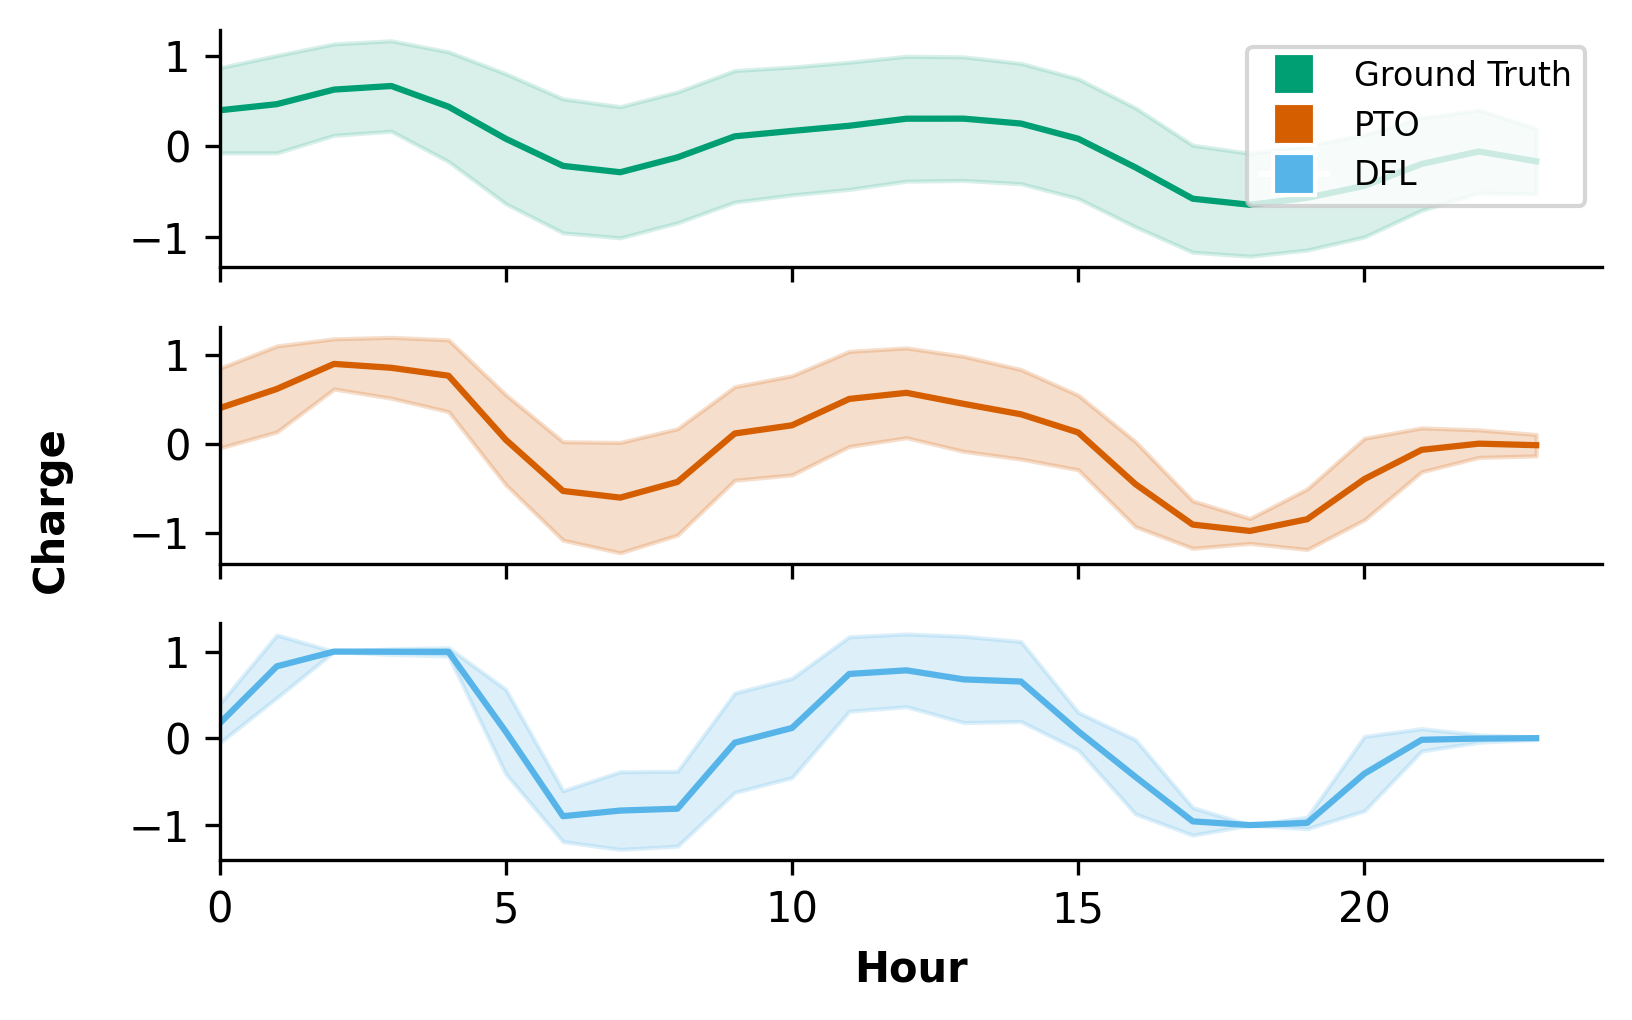

In [149]:
plt.style.use('default')

fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, ncols=1, figsize=(5.5, 3.5), dpi=300, sharex=True)

# Create an x-axis (assuming your arrays are lists of hours/steps)
hours = np.arange(len(true_test_mean))

# --- Plot 1: True Power (Top) ---
ax1.plot(hours, true_test_mean, label='True Power', color='#009E73', linestyle='-')
ax1.fill_between(hours, 
                true_test_mean -  true_test_std, 
                true_test_mean +  true_test_std, 
                color='#009E73', alpha=0.15)


# --- Plot 2: PTO (Middle) ---
ax2.plot(hours, pto_test_mean, label='PTO', color='#D55E00')
ax2.fill_between(hours, 
                pto_test_mean -  pto_test_std, 
                pto_test_mean +  pto_test_std, 
                color='#D55E00', alpha=0.2)


# --- Plot 3: DFL (Bottom) ---
ax3.plot(hours, dfl_test_mean, label='DFL', color='#56B4E9')
ax3.fill_between(hours, 
                dfl_test_mean -  dfl_test_std, 
                dfl_test_mean +  dfl_test_std, 
                color='#56B4E9', alpha=0.2)

ax3.set_xlabel('Hour', fontweight='bold', fontsize=10) # X-label only goes on the bottom plot


# --- Global Formatting ---
# Apply spine styling to all three axes at once
for ax in [ax1, ax2, ax3]:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlim(left=0)
    

legend_elements = [
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#009E73', markersize=10, label='Ground Truth'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#D55E00', markersize=10, label='PTO'),
    Line2D([0], [0], color='w', marker='s', markerfacecolor='#56B4E9', markersize=10, label='DFL'),

]
ax1.legend(handles=legend_elements, loc='upper right', frameon=True, fontsize=8)

fig.supylabel('Charge', fontweight='bold', fontsize=10)

# tight_layout prevents labels from overlapping between subplots
plt.tight_layout()
plt.savefig("plots/variance_charge.pdf", format='pdf', bbox_inches='tight') 
plt.show()